# 02. 비트 변화가 전력으로 보이는 이유

01번에서는 파형 차이로 비밀번호를 찾았습니다. 이제 MCU 내부 값과 전력 소비를 연결하는 Hamming weight와 Hamming distance를 살펴보고, 실제 TVLA로 누설 위치를 찾겠습니다. 실측 셀은 target 플래시를 지우고 번들 TinyAES 펌웨어를 기록합니다.

## Hamming weight

Hamming weight는 비트열에서 1의 개수입니다. 파형 배열이 `float32`인 것은 ADC 값을 소수로 저장했기 때문이며, 누설 모델의 Hamming weight와는 별개입니다.

0x3A = 00111010
Hamming weight = 4


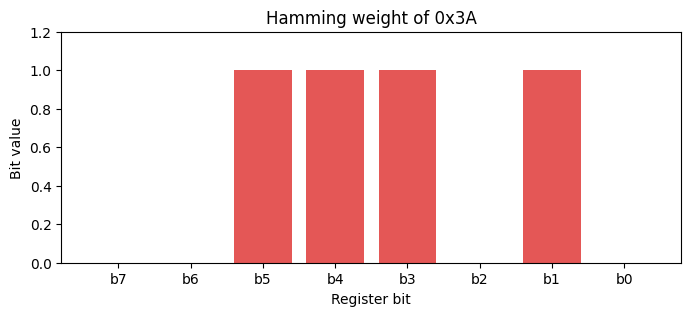

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from cw_sca_tutorial.analysis import welch_t_test

value = 0x3A
bits = np.array([(value >> bit) & 1 for bit in range(7, -1, -1)])
print(f"0x{value:02X} = {value:08b}")
print("Hamming weight =", value.bit_count())

plt.figure(figsize=(8, 3))
plt.bar(range(8), bits, color=np.where(bits, "#e45756", "#d9d9d9"))
plt.xticks(range(8), [f"b{bit}" for bit in range(7, -1, -1)])
plt.ylim(0, 1.2)
plt.xlabel("Register bit")
plt.ylabel("Bit value")
plt.title("Hamming weight of 0x3A")
plt.show()

## Hamming distance

Hamming distance는 이전 값과 새 값 사이에서 바뀐 비트 수입니다. 실제 CMOS 동적 전력은 충전·방전된 노드 수와 관련되므로 Hamming distance가 더 자연스러운 모델인 경우도 많습니다.

In [2]:
old = 0x00
new = 0xFF
distance = (old ^ new).bit_count()

print(f"old : {old:08b}")
print(f"new : {new:08b}")
print(f"xor : {old ^ new:08b}")
print("Hamming distance =", distance)

old : 00000000
new : 11111111
xor : 11111111
Hamming distance = 8


## 실제 fixed-vs-random 데이터

AES 키는 고정한 채 평문이 항상 같은 그룹 100개와 매번 달라지는 그룹 100개를 지금 측정합니다. 두 그룹은 시간 순서에 따른 드리프트가 한쪽에 몰리지 않도록 섞어서 수집합니다. 이전 측정에서는 약 10–15초가 걸릴 것으로 예상됩니다.

In [3]:
import chipwhisperer as cw
import importlib
import json

from cw_sca_tutorial.demo import repository_root
import cw_sca_tutorial.hardware as hardware

hardware = importlib.reload(hardware)
capture_aes_run = hardware.capture_aes_run

ROOT = repository_root()
devices = cw.list_devices()
assert len(devices) == 1, f"Expected one ChipWhisperer, found: {devices}"
run = capture_aes_run(
    ROOT / "firmware/prebuilt/simpleserial-aes-CWLITEARM.hex",
    trace_count=200,
    runs_root=ROOT / "runs",
    serial_number=devices[0]["sn"],
    platform_name="CWLITEARM",
    target_identification="STM32F303",
    capture_mode="fixed_vs_random",
)
metadata = json.loads((run / "metadata.json").read_text())
data = np.load(run / "traces.npz")
traces = data["traces"]
groups = data["groups"]
fixed = traces[groups == 0]
random = traces[groups == 1]

print("DATA SOURCE : MEASURED")
print("RUN         :", run.name)
print("TARGET      :", metadata["target_identity"]["user_identification"])
print(f"GROUPS      : fixed={len(fixed)}, random={len(random)}")

scope.gain.mode                          changed from low                       to high                     
scope.gain.gain                          changed from 0                         to 30                       
scope.gain.db                            changed from 5.5                       to 24.8359375               
scope.adc.basic_mode                     changed from low                       to rising_edge              
scope.adc.samples                        changed from 24445                     to 5000                     
scope.adc.trig_count                     changed from 699765220                 to 708967003                
scope.clock.adc_src                      changed from clkgen_x1                 to clkgen_x4                
scope.clock.clkgen_div                   changed from 1                         to 26                       
scope.clock.clkgen_freq                  changed from 192000000.0               to 7384615.384615385        
scope.io.tio1      

## 평균 파형과 Welch t-test

평균 파형 두 개는 비슷해 보이지만 샘플별 Welch t-test를 계산하면 반복되는 작은 차이가 드러납니다. 빨간 점선은 수업에서 자주 사용하는 `±4.5` 기준입니다.

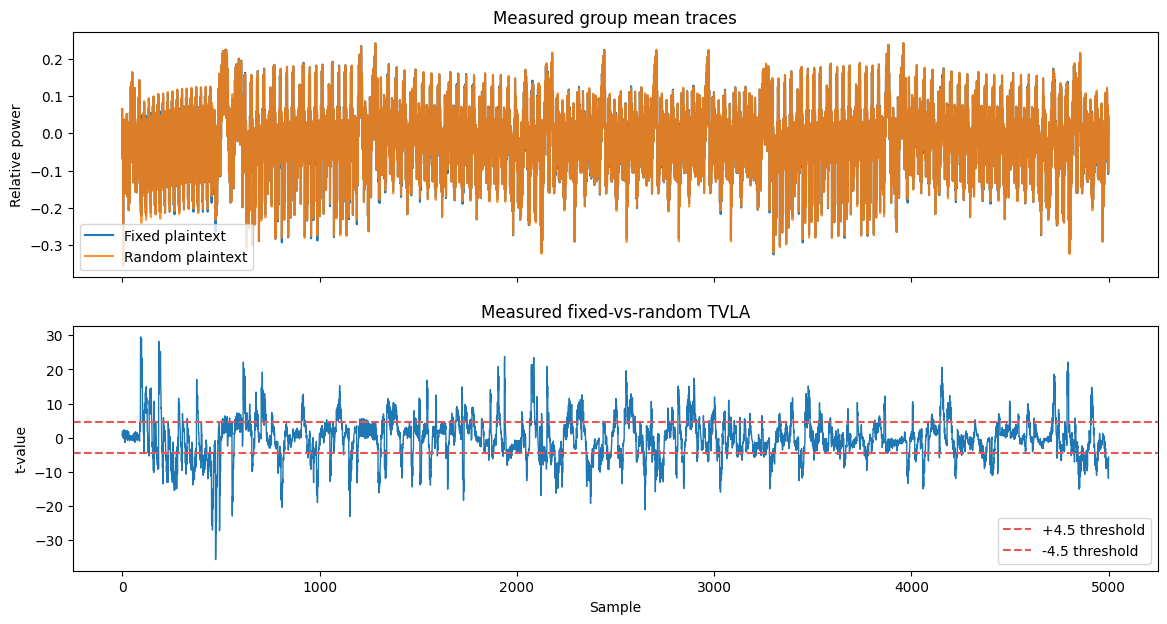

maximum |t| = 35.73 at sample 473


In [4]:
t_values = welch_t_test(traces, groups)
threshold = 4.5
peak = int(np.argmax(np.abs(t_values)))

fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
axes[0].plot(fixed.mean(axis=0), label="Fixed plaintext")
axes[0].plot(random.mean(axis=0), label="Random plaintext", alpha=.85)
axes[0].set(title="Measured group mean traces", ylabel="Relative power")
axes[0].legend()
axes[1].plot(t_values, linewidth=1)
axes[1].axhline(threshold, color="#e45756", linestyle="--", label="+4.5 threshold")
axes[1].axhline(-threshold, color="#e45756", linestyle="--", label="-4.5 threshold")
axes[1].set(title="Measured fixed-vs-random TVLA", xlabel="Sample", ylabel="t-value")
axes[1].legend()
plt.show()

print(f"maximum |t| = {abs(t_values[peak]):.2f} at sample {peak}")
assert np.max(np.abs(t_values)) > threshold

## 파형 수를 늘리면

각 그룹에서 사용하는 파형 수를 늘리며 최대 `|t|`를 다시 계산합니다. TVLA는 누설 위치를 찾는 검사이며, 이 단계에서는 아직 키 후보를 사용하지 않습니다.

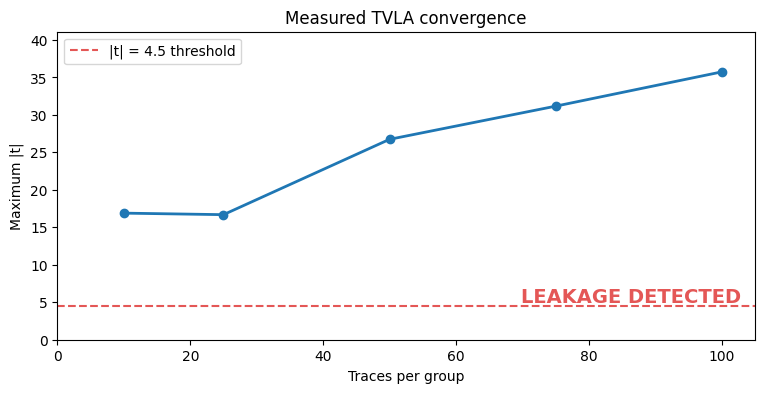

In [5]:
from IPython.display import clear_output, display
import time

counts = [10, 25, 50, 75, 100]
max_t = []
for count in counts:
    subset = np.concatenate([
        np.flatnonzero(groups == 0)[:count],
        np.flatnonzero(groups == 1)[:count],
    ])
    max_t.append(float(np.max(np.abs(welch_t_test(traces[subset], groups[subset])))))

    fig, ax = plt.subplots(figsize=(9, 4))
    ax.plot(counts[:len(max_t)], max_t, "o-", linewidth=2)
    ax.axhline(4.5, color="#e45756", linestyle="--", label="|t| = 4.5 threshold")
    ax.set_xlim(0, 105)
    ax.set_ylim(0, max(8, max(max_t) * 1.15))
    ax.set(title="Measured TVLA convergence", xlabel="Traces per group", ylabel="Maximum |t|")
    status = "LEAKAGE DETECTED" if max_t[-1] > 4.5 else "collecting traces..."
    ax.text(.98, .12, status, transform=ax.transAxes, ha="right", fontsize=14, weight="bold", color="#e45756")
    ax.legend(loc="upper left")
    clear_output(wait=True)
    display(fig)
    plt.close(fig)
    if count < counts[-1]:
        time.sleep(.6)